In [39]:
from pathlib import Path

zip_path = Path("/content/faceShape_70_10_20.zip")
print("ZIP found:", zip_path.is_file())

ZIP found: True


In [40]:
from zipfile import ZipFile

data_dir = Path("/content/faceShape_70_10_20")

with ZipFile(zip_path) as archive:
    archive.extractall(data_dir)

print("Extracted folders:", sorted(p.name for p in data_dir.iterdir() if p.is_dir()))

Extracted folders: ['test', 'train', 'valid']


In [41]:
from collections import Counter

from torchvision.datasets import ImageFolder

test_data = ImageFolder(data_dir / "test")
counts = Counter(test_data.classes[label] for label in test_data.targets)

print("Test images:", len(test_data))
for label, count in sorted(counts.items()):
    print(f"{label}: {count}")

Test images: 3147
heart: 503
long: 597
oval: 626
round: 690
square: 731


In [42]:
from inference_sdk import InferenceConfiguration, InferenceHTTPClient

print("Roboflow SDK imported successfully")

Roboflow SDK imported successfully


In [43]:
for split in ("train", "valid", "test"):
    data = ImageFolder(data_dir / split)
    label_counts = Counter(data.classes[i] for i in data.targets)
    print(split, dict(sorted(label_counts.items())))

train {'heart': 1761, 'long': 2091, 'oval': 2189, 'round': 2415, 'square': 2558}
valid {'heart': 251, 'long': 299, 'oval': 313, 'round': 345, 'square': 365}
test {'heart': 503, 'long': 597, 'oval': 626, 'round': 690, 'square': 731}


In [44]:
from getpass import getpass

client = InferenceHTTPClient(
    api_url="https://serverless.roboflow.com",
    api_key=getpass("Roboflow API key: ").strip(),
).configure(InferenceConfiguration(api_key_transport="header"))

Roboflow API key: ··········


In [45]:
from random import Random

samples = list(test_data.samples)
Random(42).shuffle(samples)
seen = Counter()
pilot_results = []

for path, label_id in samples:
    actual = test_data.classes[label_id].lower()
    if seen[actual] >= 2:
        continue

    response = client.infer(path, model_id="faceshape-atkte/4")
    predicted = response["top"].lower()
    pilot_results.append((actual, predicted))
    seen[actual] += 1
    print(f"Actual: {actual} | Predicted: {predicted}")

correct = sum(actual == predicted for actual, predicted in pilot_results)
print(f"Pilot: {correct}/{len(pilot_results)} correct")

Actual: oval | Predicted: oval
Actual: square | Predicted: square
Actual: round | Predicted: round
Actual: round | Predicted: round
Actual: square | Predicted: square
Actual: oval | Predicted: heart
Actual: long | Predicted: long
Actual: long | Predicted: long
Actual: heart | Predicted: heart
Actual: heart | Predicted: heart
Pilot: 9/10 correct


In [46]:
import json
from pathlib import Path

results_path = Path("/content/faceshape_v4_test_results.jsonl")
completed = set()

if results_path.exists():
    completed = {
        json.loads(line)["path"]
        for line in results_path.read_text().splitlines()
        if line.strip()
    }

with results_path.open("a", encoding="utf-8") as output:
    for path, label_id in test_data.samples:
        if path in completed:
            continue

        response = client.infer(path, model_id="faceshape-atkte/4")
        row = {
            "path": path,
            "actual": test_data.classes[label_id].lower(),
            "predicted": response["top"].lower(),
        }
        output.write(json.dumps(row) + "\n")
        output.flush()
        completed.add(path)

        if len(completed) % 25 == 0:
            print(f"Completed {len(completed)}/{len(test_data)}", flush=True)

print(f"Finished: {len(completed)}/{len(test_data)}")

Completed 25/3147
Completed 50/3147
Completed 75/3147
Completed 100/3147
Completed 125/3147
Completed 150/3147
Completed 175/3147
Completed 200/3147
Completed 225/3147
Completed 250/3147
Completed 275/3147
Completed 300/3147
Completed 325/3147
Completed 350/3147
Completed 375/3147
Completed 400/3147
Completed 425/3147
Completed 450/3147
Completed 475/3147
Completed 500/3147
Completed 525/3147
Completed 550/3147
Completed 575/3147
Completed 600/3147
Completed 625/3147
Completed 650/3147
Completed 675/3147
Completed 700/3147
Completed 725/3147
Completed 750/3147
Completed 775/3147
Completed 800/3147
Completed 825/3147
Completed 850/3147
Completed 875/3147
Completed 900/3147
Completed 925/3147
Completed 950/3147
Completed 975/3147
Completed 1000/3147
Completed 1025/3147
Completed 1050/3147
Completed 1075/3147
Completed 1100/3147
Completed 1125/3147
Completed 1150/3147
Completed 1175/3147
Completed 1200/3147
Completed 1225/3147
Completed 1250/3147
Completed 1275/3147
Completed 1300/3147
Co

In [52]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

results = pd.read_json(results_path, lines=True)

assert len(results) == results["path"].nunique() == len(test_data)

actual = results["actual"]
predicted = results["predicted"]

shapes = ["heart", "long", "oval", "round", "square"]

print(f"Test accuracy: {accuracy_score(actual, predicted):.2%}")

print(classification_report(
    actual,
    predicted,
    labels=shapes,
    digits=4,
    zero_division=0
))

matrix = pd.crosstab(
    actual,
    predicted,
    rownames=["Actual"],
    colnames=["Predicted"]
)

display(matrix.reindex(
    index=shapes,
    columns=shapes,
    fill_value=0
))

Test accuracy: 97.62%
              precision    recall  f1-score   support

       heart     0.9784    0.9920    0.9852       503
        long     0.9586    0.9698    0.9642       597
        oval     0.9805    0.9617    0.9710       626
       round     0.9884    0.9855    0.9869       690
      square     0.9740    0.9740    0.9740       731

    accuracy                         0.9762      3147
   macro avg     0.9760    0.9766    0.9763      3147
weighted avg     0.9762    0.9762    0.9762      3147



Predicted,heart,long,oval,round,square
Actual,,,,,
heart,499,1,1,0,2
long,5,579,5,0,8
oval,5,9,602,4,6
round,1,1,5,680,3
square,0,14,1,4,712


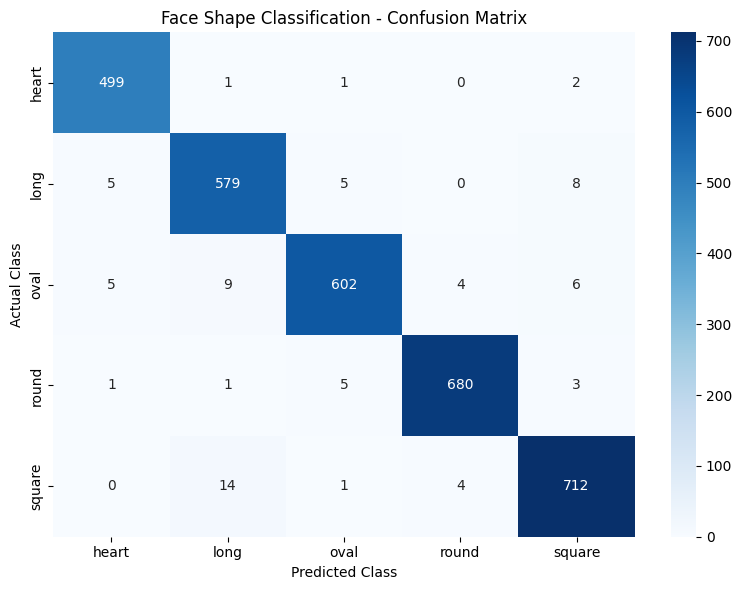

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

shapes = ["heart", "long", "oval", "round", "square"]

cm = confusion_matrix(actual, predicted, labels=shapes)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=shapes,
    yticklabels=shapes
)

plt.title("Face Shape Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig("/content/face_shape_confusion_matrix.png",
            dpi=300, bbox_inches="tight")

plt.show()

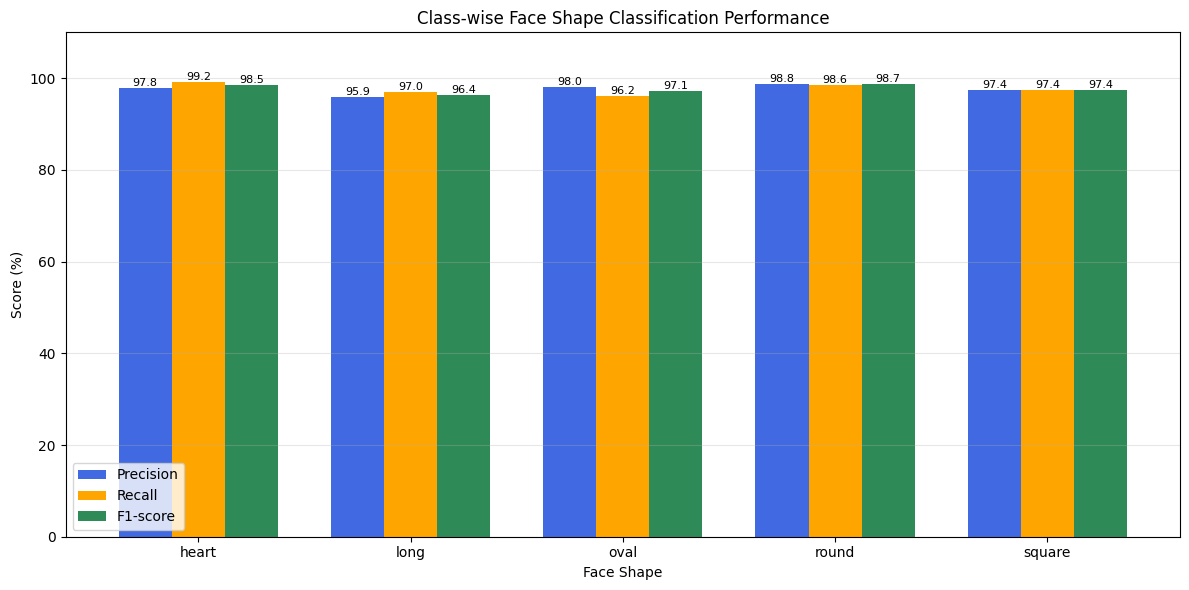

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

report = classification_report(
    actual,
    predicted,
    labels=shapes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

class_metrics = report_df.loc[
    shapes, ["precision", "recall", "f1-score"]
] * 100

ax = class_metrics.plot(
    kind="bar",
    figsize=(12, 6),
    color=["royalblue", "orange", "seagreen"],
    width=0.75
)

plt.title("Class-wise Face Shape Classification Performance")
plt.xlabel("Face Shape")
plt.ylabel("Score (%)")
plt.ylim(0, 110)
plt.xticks(rotation=0)
plt.legend(["Precision", "Recall", "F1-score"])
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8)

plt.tight_layout()

plt.savefig(
    "/content/face_shape_classwise_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

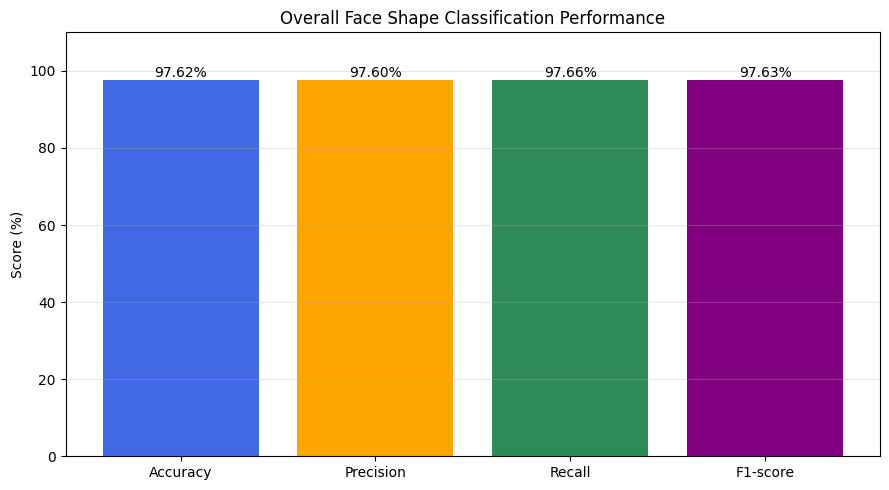

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

metrics = {
    "Accuracy": accuracy_score(actual, predicted) * 100,
    "Precision": precision_score(
        actual, predicted, labels=shapes,
        average="macro", zero_division=0
    ) * 100,
    "Recall": recall_score(
        actual, predicted, labels=shapes,
        average="macro", zero_division=0
    ) * 100,
    "F1-score": f1_score(
        actual, predicted, labels=shapes,
        average="macro", zero_division=0
    ) * 100
}

plt.figure(figsize=(9, 5))

bars = plt.bar(
    metrics.keys(),
    metrics.values(),
    color=["royalblue", "orange", "seagreen", "purple"]
)

plt.bar_label(bars, fmt="%.2f%%")
plt.ylim(0, 110)
plt.ylabel("Score (%)")
plt.title("Overall Face Shape Classification Performance")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/face_shape_overall_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

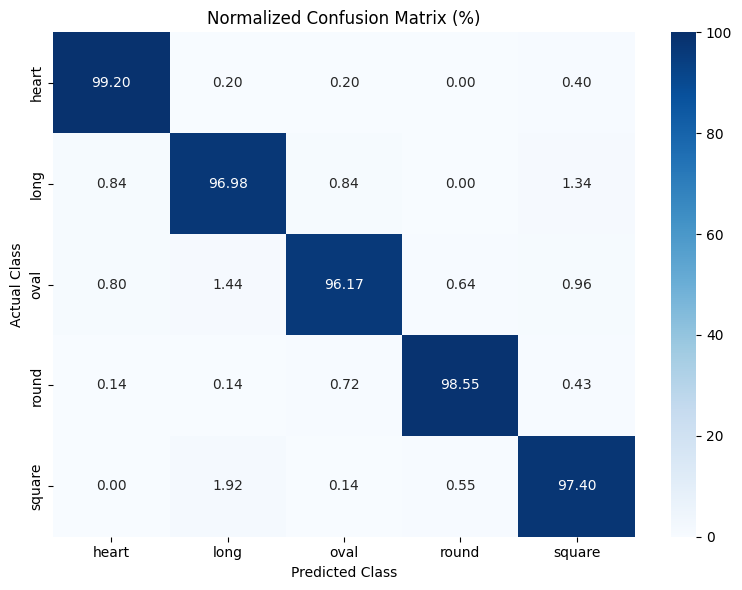

In [56]:
cm_normalized = confusion_matrix(
    actual,
    predicted,
    labels=shapes,
    normalize="true"
) * 100

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=shapes,
    yticklabels=shapes,
    vmin=0,
    vmax=100
)

plt.title("Normalized Confusion Matrix (%)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

plt.savefig(
    "/content/face_shape_normalized_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Total images: 3147
Correct predictions: 3072
Incorrect predictions: 75


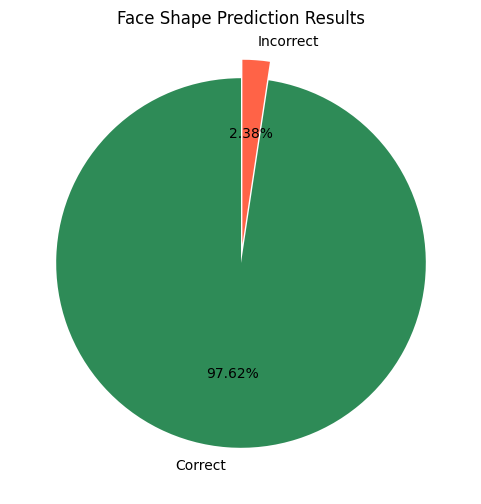

In [57]:
correct = int((actual == predicted).sum())
incorrect = int((actual != predicted).sum())

print("Total images:", len(actual))
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)

plt.figure(figsize=(7, 6))

plt.pie(
    [correct, incorrect],
    labels=["Correct", "Incorrect"],
    autopct="%1.2f%%",
    colors=["seagreen", "tomato"],
    explode=[0, 0.1],
    startangle=90
)

plt.title("Face Shape Prediction Results")

plt.savefig(
    "/content/face_shape_prediction_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
incorrect_results = results[
    results["actual"] != results["predicted"]
].copy()

error_summary = (
    incorrect_results
    .groupby(["actual", "predicted"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(error_summary)

incorrect_results.to_csv(
    "/content/face_shape_incorrect_predictions.csv",
    index=False
)

,actual,predicted,count
14,square,long,14
7,oval,long,9
5,long,square,8
9,oval,square,6
6,oval,heart,5
4,long,oval,5
12,round,oval,5
3,long,heart,5
8,oval,round,4
16,square,round,4


In [59]:
report_df.to_csv(
    "/content/face_shape_classification_report.csv"
)

pd.DataFrame([metrics]).to_csv(
    "/content/face_shape_overall_metrics.csv",
    index=False
)

results.to_csv(
    "/content/face_shape_all_predictions.csv",
    index=False
)

print("All evaluation metrics saved successfully")

All evaluation metrics saved successfully


In [60]:
import zipfile
from pathlib import Path
from google.colab import files

output_files = [
    "face_shape_confusion_matrix.png",
    "face_shape_classwise_metrics.png",
    "face_shape_overall_metrics.png",
    "face_shape_normalized_matrix.png",
    "face_shape_prediction_results.png",
    "face_shape_incorrect_predictions.csv",
    "face_shape_classification_report.csv",
    "face_shape_overall_metrics.csv",
    "face_shape_all_predictions.csv"
]

zip_output = "/content/face_shape_final_results.zip"

with zipfile.ZipFile(
    zip_output, "w", zipfile.ZIP_DEFLATED
) as archive:

    for filename in output_files:

        path = Path("/content") / filename

        if path.exists():
            archive.write(path, arcname=filename)
            print("Saved:", filename)
        else:
            print("Missing:", filename)

files.download(zip_output)

Saved: face_shape_confusion_matrix.png
Saved: face_shape_classwise_metrics.png
Saved: face_shape_overall_metrics.png
Saved: face_shape_normalized_matrix.png
Saved: face_shape_prediction_results.png
Saved: face_shape_incorrect_predictions.csv
Saved: face_shape_classification_report.csv
Saved: face_shape_overall_metrics.csv
Saved: face_shape_all_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>